# A1-1 · H&M 고객 구매 패턴과 RFM 분석

**분석 질문:** 선택한 6개월 동안 어떤 고객이 최근까지 자주 구매하고 많은 금액을 지출했을까요?

현재 저장소 최상위의 데이터 5개를 읽습니다. 상품명·이미지는 전처리 실습에 사용하고, RFM은 거래 기록으로 계산합니다. 원본 데이터 파일은 수정하지 않습니다.

처음에는 각 코드 셀의 실행 버튼으로 위에서부터 한 셀씩 실행하고, 바로 아래 설명과 결과를 함께 읽으세요. 셀 안의 Python 코드는 터미널이 아닌 이 노트북에서 실행합니다. 최종 확인은 **커널 재시작 → 모두 실행 → 저장** 순서입니다.

이 노트북에는 실행 결과가 저장되어 있습니다. 모든 코드 셀을 다시 실행하면 결과와 README의 자동 분석 결과 영역이 갱신됩니다.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline

# 프로젝트 폴더 또는 notebooks 폴더에서 시작해도 동일한 입력을 찾습니다.
required_files = ("transactions.csv", "customers.csv", "articles.csv",
                  "images.npz", "provenance.json", "src/pipeline.py")
current = Path.cwd().resolve()
ROOT = next((folder for folder in (current, *current.parents)
             if all((folder / name).is_file() for name in required_files)), None)
if ROOT is None:
    raise FileNotFoundError("CSV 3개·images.npz·provenance.json·src/pipeline.py가 있는 프로젝트를 VS Code로 여세요.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.pipeline import DataAnalyzer

DATA_DIR = ROOT
analyzer = DataAnalyzer(DATA_DIR)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (9, 4.8), "figure.dpi": 120})
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 35)
shown_charts = set()

def show_chart(number):
    plt.tight_layout()
    plt.show()
    plt.close()
    shown_charts.add(number)

print("실행 중인 Python:", sys.executable)
print("프로젝트 및 데이터 위치:", ROOT)
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)


Matplotlib is building the font cache; this may take a moment.


실행 중인 Python: /Users/dave17code0177/Desktop/a1-1-hnm-customer-analysis/.venv/bin/python
프로젝트 및 데이터 위치: /Users/dave17code0177/Desktop/a1-1-hnm-customer-analysis
NumPy: 2.3.5 | Pandas: 2.2.3


## 1. 데이터 로드와 분석 단위

세 CSV를 고객 ID와 상품 ID로 연결합니다. 거래 한 행에 고객·상품의 설명을 붙이므로 같은 고객의 나이가 여러 번 나올 수 있습니다. 가격 통계는 거래 표에서, 나이 통계는 고객별 한 행인 고객 표에서 계산합니다.

`head()`는 앞부분 미리보기, `info()`는 열과 자료형 확인, `describe()`는 숫자 요약입니다. 고객 ID는 화면 미리보기에서만 짧게 표시하며 실제 연결용 ID와 상품 ID 앞의 0은 보존합니다.


In [2]:
df = analyzer.load_data()
base_shape = df.shape
raw_price = df.price.copy()
preview = df.head().copy()
preview["customer_id"] = preview.customer_id.str[:8] + "…"
display(preview)
df.info()
print("가격 통계: 거래 기록 기준")
display(df[["price"]].describe())
print("나이 통계: 고객별 한 행 기준, 결측 대치 전")
display(analyzer.customers[["age"]].describe())
meta = analyzer.meta
display(Markdown(
    f"**관찰:** 조인 결과는 **{len(df):,}행 × {df.shape[1]}컬럼**, 고객 **{df.customer_id.nunique():,}명**, "
    f"상품 **{df.article_id.nunique():,}개**이다. 관찰 기간은 {meta['window_start']}~{meta['reference_date']}이며 "
    f"표본은 해당 기간 구매 고객 {meta['eligible_customers']:,}명 중 선택되었다. "
    f"가격 중앙값은 {df.price.median():.4f}(제공 단위)이다.\n\n"
    "**의미:** 같은 고객·상품이 여러 거래 행에 나타날 수 있으므로, 고객 통계와 상품 통계는 각각 한 행으로 계산한다. "
    "이 표본을 전체 H&M 고객의 분포로 일반화하지 않는다."))


,order_date,customer_id,article_id,price,sales_channel_id,prod_name,product_type_name,product_group_name,colour_group_name,club_member_status,age
0,2020-03-23,0107b0f1…,0832361003,0.011898,2,Mona,Top,Garment Upper body,Light Beige,ACTIVE,33.0
1,2020-03-23,0107b0f1…,0760123005,0.014881,2,Mona polo,Top,Garment Upper body,Red,ACTIVE,33.0
2,2020-03-23,0107b0f1…,0822115001,0.022322,2,Pola seamless leggings,Leggings/Tights,Garment Lower body,Black,ACTIVE,33.0
3,2020-03-23,3db6ac02…,0824526003,0.067780,2,JENNIFER LONG,Blazer,Garment Upper body,Black,ACTIVE,32.0
4,2020-03-23,3db6ac02…,0832361003,0.013542,2,Mona,Top,Garment Upper body,Light Beige,ACTIVE,32.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11153 entries, 0 to 11152
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_date          11153 non-null  datetime64[ns]
 1   customer_id         11153 non-null  object        
 2   article_id          11153 non-null  object        
 3   price               11153 non-null  float64       
 4   sales_channel_id    11153 non-null  category      
 5   prod_name           11153 non-null  object        
 6   product_type_name   11153 non-null  category      
 7   product_group_name  11153 non-null  category      
 8   colour_group_name   11153 non-null  category      
 9   club_member_status  11112 non-null  object        
 10  age                 11121 non-null  float64       
dtypes: category(4), datetime64[ns](1), float64(2), object(4)
memory usage: 658.3+ KB
가격 통계: 거래 기록 기준


,price
count,11153.000000
mean,0.026917
std,0.016698
min,0.000831
25%,0.016932
50%,0.025407
75%,0.033881
max,0.303390


나이 통계: 고객별 한 행 기준, 결측 대치 전


,age
count,997.000000
mean,36.080241
std,14.228400
min,17.000000
25%,24.000000
50%,31.000000
75%,49.000000
max,78.000000


**관찰:** 조인 결과는 **11,153행 × 11컬럼**, 고객 **1,000명**, 상품 **6,055개**이다. 관찰 기간은 2020-03-23~2020-09-22이며 표본은 해당 기간 구매 고객 746,682명 중 선택되었다. 가격 중앙값은 0.0254(제공 단위)이다.

**의미:** 같은 고객·상품이 여러 거래 행에 나타날 수 있으므로, 고객 통계와 상품 통계는 각각 한 행으로 계산한다. 이 표본을 전체 H&M 고객의 분포로 일반화하지 않는다.

## 2. 그룹별 결측치 대치와 멀티모달 피처

회원 상태별 나이 중앙값은 고객 테이블에서 계산한다. 그룹에 관측 나이가 없으면 전체 표본 고객의 중앙값을 사용한다. 이미지는 `(N, H, W, 3)` 배열의 뒤 세 축을 축약해 이미지별 평균·표준편차를 계산한다. 이미지 없는 상품의 거래는 유지하며 피처는 결측으로 표시한다.

나이가 없는 고객만 찾아 표시한 뒤, 회원 상태가 같은 고객들의 나이 중앙값으로 채웁니다. 이미지가 없는 상품의 거래는 삭제하지 않습니다.


In [3]:
missing_age_before = analyzer.customers.loc[analyzer.customers.age.isna(), ["customer_id", "club_member_status", "age"]].copy()
analyzer.handle_missing_values(strategy="group_median", group_col="club_member_status", column="age")
age_preview = missing_age_before.rename(columns={"age": "age_before"})
age_preview["age_after"] = age_preview.customer_id.map(analyzer.customers.set_index("customer_id").age)
age_preview["customer_id"] = age_preview.customer_id.str[:8] + "…"
display(age_preview)
analyzer.engineer_features()
df = analyzer.df
display(df[["article_id", "prod_name", "name_length", "image_mean", "image_std", "image_missing"]].head(3))
filled_age = next(r["before_missing"] for r in analyzer.audit if r["target"] == "customer.age")
image_missing = len(analyzer.articles) - len(analyzer.image_ids)
image_coverage = len(analyzer.image_ids) / len(analyzer.articles) * 100
display(Markdown(
    f"**관찰:** 나이 결측 **{filled_age:,}명**을 대치했고, 상품 이미지 **{len(analyzer.image_ids):,}개**에서 "
    f"피처를 추출했다(상품 기준 연결률 **{image_coverage:.2f}%**, 누락 **{image_missing:,}개**). "
    f"입력 이미지 배열의 형태는 **{analyzer.pixels.shape}**이다.\n\n"
    "**의미:** 결측 나이의 대치는 추정이며 관측값과 구별한다. 이미지 통계는 축소 RGB 배열 전체의 픽셀 통계로, "
    "배경·조명·포장까지 반영하므로 상품의 품질이나 고객 선호로 바로 해석할 수 없다."))


,customer_id,club_member_status,age_before,age_after
168,294abeef…,ACTIVE,NaN,31.0
557,90aa01d3…,ACTIVE,NaN,31.0
765,c22a2a94…,ACTIVE,NaN,31.0


,article_id,prod_name,name_length,image_mean,image_std,image_missing
0,0832361003,Mona,4,222.104492,17.454880,False
1,0760123005,Mona polo,9,183.256022,85.076484,False
2,0822115001,Pola seamless leggings,22,175.178792,88.283688,False


**관찰:** 나이 결측 **3명**을 대치했고, 상품 이미지 **6,047개**에서 피처를 추출했다(상품 기준 연결률 **99.87%**, 누락 **8개**). 입력 이미지 배열의 형태는 **(6047, 64, 64, 3)**이다.

**의미:** 결측 나이의 대치는 추정이며 관측값과 구별한다. 이미지 통계는 축소 RGB 배열 전체의 픽셀 통계로, 배경·조명·포장까지 반영하므로 상품의 품질이나 고객 선호로 바로 해석할 수 없다.

## 3. IQR 탐지와 처리 기록

Q1−1.5×IQR, Q3+1.5×IQR를 직접 계산한다. 원본 `price`를 유지하고, 분포 비교용 `price_iqr`만 경계값으로 제한한다. 유효한 고액 구매를 RFM에서 없애지 않기 위한 선택이다.


In [4]:
outliers = analyzer.detect_outliers(column="price", threshold=1.5, treatment="clip")
df = analyzer.df
out = analyzer.outlier_report
quality = pd.DataFrame(analyzer.audit + [{
    "target": "transaction.price", "checked": len(df), "before_missing": 0, "after_missing": 0,
    "action": f"IQR 극단값 {out['count']:,}행; 비교용 컬럼만 clip"}])
display(quality)
display(Markdown(
    f"**관찰:** Q1={out['q1']:.4f}, Q3={out['q3']:.4f}, IQR={out['iqr']:.4f}, "
    f"경계=[{out['lower']:.4f}, {out['upper']:.4f}]이며 **{out['count']:,}행({out['rate']:.2%})**이 탐지되었다.\n\n"
    "**의미:** 이 기준은 분포상 극단값을 표시한다. 오류 여부는 별도 확인이 필요하므로 원본 가격과 모든 유효 거래는 보존한다."))


,target,checked,before_missing,after_missing,action
0,customer.club_member_status,1000,3,0,Unknown으로 표시
1,customer.age,1000,3,0,group_median; 전체 통계 대체 0명
2,product.image,6055,8,8,이미지 특성만 결측으로 유지; 거래는 보존
3,transaction.price,11153,0,0,IQR 극단값 535행; 비교용 컬럼만 clip


**관찰:** Q1=0.0169, Q3=0.0339, IQR=0.0169, 경계=[-0.0085, 0.0593]이며 **535행(4.80%)**이 탐지되었다.

**의미:** 이 기준은 분포상 극단값을 표시한다. 오류 여부는 별도 확인이 필요하므로 원본 가격과 모든 유효 거래는 보존한다.

## 4. 기술통계

가격은 거래별, 나이는 고객별, 상품명과 이미지 특성은 상품별 통계다. 표의 50%가 중앙값, 25%·75%가 사분위수다. 표준편차는 표본 통계(ddof=1)다.


In [5]:
stats = analyzer.summary_statistics()
display(stats.round(4))
price_stats = stats["price / transaction"]
display(Markdown(
    f"**관찰:** 가격 평균 **{price_stats['mean']:.4f}**, 중앙값 **{price_stats['50%']:.4f}**, "
    f"표준편차 **{price_stats['std']:.4f}**, Q1~Q3는 **{price_stats['25%']:.4f}~{price_stats['75%']:.4f}**이다. "
    f"대치 후 고객 나이 중앙값은 **{analyzer.customers.age.median():.1f}세**이며, "
    f"상품 이미지 평균 픽셀값의 평균은 **{analyzer.image_features.image_mean.mean():.2f}/255**이다.\n\n"
    "**의미:** 평균과 중앙값의 차이, 표준편차와 사분위 범위를 함께 봐야 가격의 중심과 퍼짐을 설명할 수 있다. "
    "나이 통계에는 대치값이 포함되며, 이미지 밝기 수치는 구매금액의 원인을 설명하지 않는다."))


,price / transaction,age / customer,name_length / product,image_mean / product,image_std / product
count,11153.0000,1000.0000,6055.0000,6047.0000,6047.0000
mean,0.0269,36.0650,15.8789,197.4976,54.0006
std,0.0167,14.2097,6.2186,26.3069,30.0770
min,0.0008,17.0000,2.0000,30.0639,2.3994
25%,0.0169,24.0000,11.0000,179.0452,26.7734
50%,0.0254,31.0000,16.0000,201.7345,56.4251
75%,0.0339,49.0000,20.0000,219.2751,81.6464
max,0.3034,78.0000,30.0000,252.6775,117.3157


**관찰:** 가격 평균 **0.0269**, 중앙값 **0.0254**, 표준편차 **0.0167**, Q1~Q3는 **0.0169~0.0339**이다. 대치 후 고객 나이 중앙값은 **31.0세**이며, 상품 이미지 평균 픽셀값의 평균은 **197.50/255**이다.

**의미:** 평균과 중앙값의 차이, 표준편차와 사분위 범위를 함께 봐야 가격의 중심과 퍼짐을 설명할 수 있다. 나이 통계에는 대치값이 포함되며, 이미지 밝기 수치는 구매금액의 원인을 설명하지 않는다.

## 5. RFM 점수와 고객 세분화

R=원본 최종 거래일−고객 마지막 구매일, F=서로 다른 구매일 수, M=원본 `price` 합계. M은 제공 단위이며 실제 통화나 LTV로 환산하지 않는다.

1~4점 중 높은 점수가 더 최근·고빈도·고금액을 뜻한다. 평균 순위 백분위×4의 올림으로 동점은 같은 점수다. 아래 조건을 위에서부터 적용해 고객을 한 그룹에만 배정한다.

| 그룹 | 점수 조건 | 특징 |
|---|---|---|
| VIP | R≥3, F≥3, M≥3 | 최근·고빈도·고금액 |
| Loyal | 앞 조건 제외, R≥2, F≥3 | 비교적 최근까지 자주 구매 |
| RecentLowFreq | 앞 조건 제외, R≥3, F<3 | 최근 구매·낮은 구매 빈도 |
| AtRisk | 앞 조건 제외, R=1 | 표본 내 상대적으로 긴 미구매 기간 |
| Regular | 나머지 | 일반 고객 |

RecentLowFreq는 신규 가입을 뜻하지 않으며, AtRisk도 이탈 확정을 뜻하지 않는다.


In [6]:
rfm = analyzer.calculate_rfm(customer_col="customer_id", date_col="order_date", amount_col="price",
                             reference_date=meta["reference_date"])
segments = analyzer.segment_summary()
display(segments[["customers", "customer_pct", "mean_recency_days", "mean_purchase_days",
                  "mean_monetary", "monetary_pct"]].round(2))
display(Markdown(
    f"**관찰:** 기준일은 **{analyzer.reference_date.date()}**이고, **{len(rfm):,}명**을 "
    f"**{rfm.segment.nunique()}개 그룹**으로 분류했다. 고객별 구매일 수 중앙값은 "
    f"**{rfm.Frequency.median():.1f}일**, 마지막 구매 후 경과일 중앙값은 **{rfm.Recency.median():.1f}일**이다.\n\n"
    "**의미:** 관찰 기간과 점수 기준을 공유해야 그룹을 재현할 수 있다. 실제 캠페인 대상은 그룹명뿐 아니라 각 그룹의 구매금액·미구매 기간을 함께 확인해 정한다."))


,customers,customer_pct,mean_recency_days,mean_purchase_days,mean_monetary,monetary_pct
segment,,,,,,
VIP,302,30.2,21.05,6.06,0.62,62.01
Loyal,223,22.3,59.13,2.87,0.24,17.74
RecentLowFreq,123,12.3,25.63,1.00,0.10,4.28
AtRisk,250,25.0,136.42,1.45,0.16,13.04
Regular,102,10.2,79.63,1.00,0.09,2.92


**관찰:** 기준일은 **2020-09-22**이고, **1,000명**을 **5개 그룹**으로 분류했다. 고객별 구매일 수 중앙값은 **2.0일**, 마지막 구매 후 경과일 중앙값은 **54.0일**이다.

**의미:** 관찰 기간과 점수 기준을 공유해야 그룹을 재현할 수 있다. 실제 캠페인 대상은 그룹명뿐 아니라 각 그룹의 구매금액·미구매 기간을 함께 확인해 정한다.

## 6. 시각화 6개

각 그림 아래의 숫자와 해석을 읽고, 표와 그래프가 같은 내용을 보여주는지 확인하세요. 축 이름은 Windows·Mac의 한글 글꼴 차이로 인한 깨짐을 줄이기 위해 영어로 표시하고 설명은 한글로 제공합니다. 차트는 노트북 출력에 표시됩니다.

1. 히스토그램: 원래 가격은 어느 구간에 많이 모여 있나요?
2. 박스플롯: IQR 경계로 제한한 가격은 원래 가격과 어떻게 다른가요?
3. 막대그래프: 고객 그룹마다 몇 명이 있나요?
4. 히트맵: 최근 구매·구매일 수·구매금액은 어떻게 함께 변하나요?
5. 산점도: 같은 구매일 수라도 금액이 다른가요?
6. 선그래프: 관찰 기간의 월별 구매금액은 어떻게 다른가요?

6개월의 날짜 구간이 3월~9월의 **7개 달력월**에 걸쳐 있으므로 첫 달과 마지막 달은 일부 날짜만 포함됩니다. 그래프에도 partial로 표시합니다.


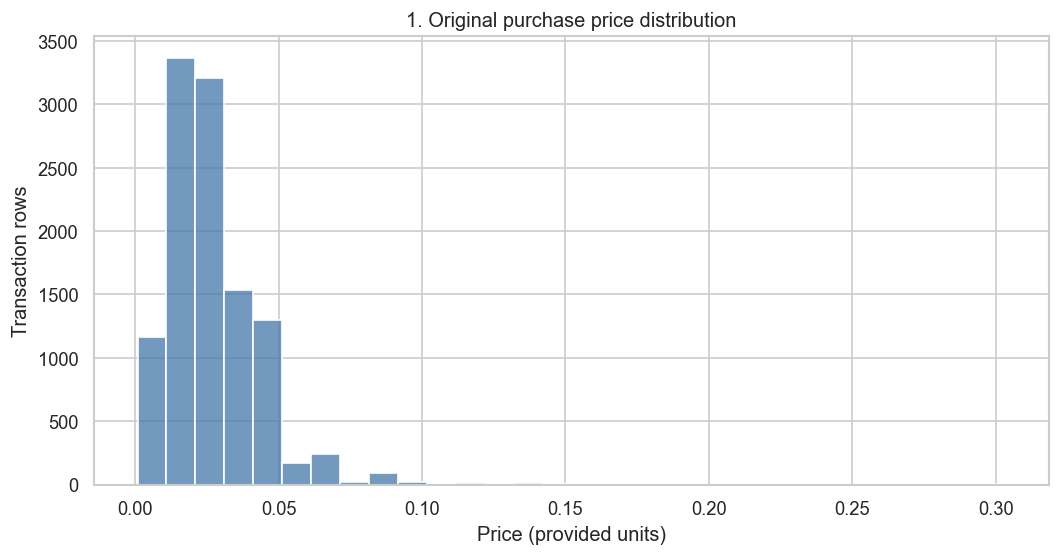

**관찰:** 거래 가격 범위는 **0.0008~0.3034**, 중앙값은 **0.0254**이다. **의미:** 긴 꼬리와 중심 구간을 확인하고 대표 가격은 평균과 중앙값을 함께 제시한다.

In [7]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="price", bins=30, ax=ax, color="#4477AA")
ax.set(title="1. Original purchase price distribution", xlabel="Price (provided units)", ylabel="Transaction rows")
show_chart(1)
display(Markdown(f"**관찰:** 거래 가격 범위는 **{df.price.min():.4f}~{df.price.max():.4f}**, 중앙값은 **{df.price.median():.4f}**이다. "
                 "**의미:** 긴 꼬리와 중심 구간을 확인하고 대표 가격은 평균과 중앙값을 함께 제시한다."))


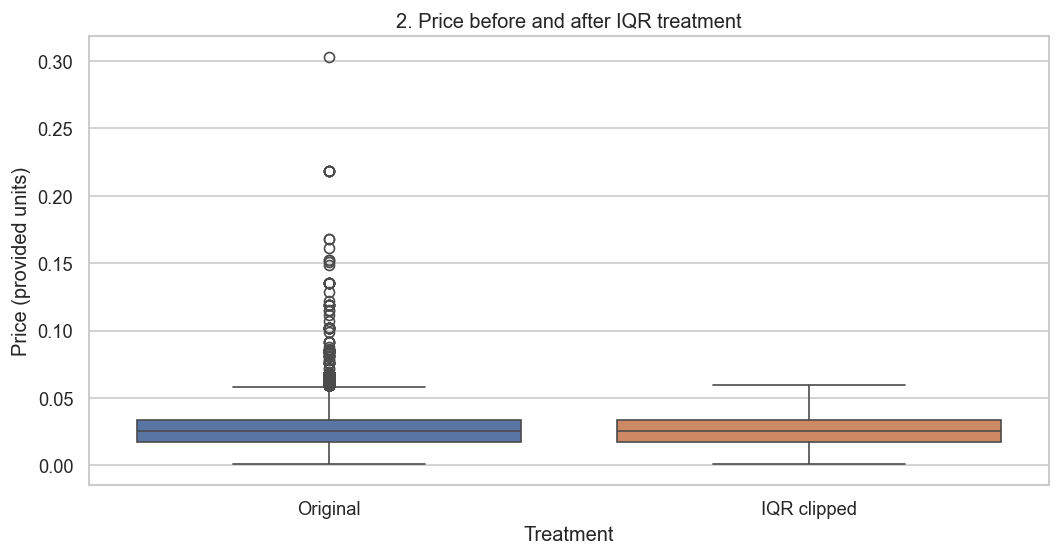

**관찰:** 가격 표준편차는 **0.0167 → 0.0137**, 최댓값은 **0.3034 → 0.0593**이다. **의미:** 극단값 제한의 영향을 비교할 수 있다. RFM과 월별 합계에는 처리 전 원본 가격을 사용한다.

In [8]:
fig, ax = plt.subplots()
sns.boxplot(data=df[["price", "price_iqr"]].rename(columns={"price": "Original", "price_iqr": "IQR clipped"}), ax=ax)
ax.set(title="2. Price before and after IQR treatment", xlabel="Treatment", ylabel="Price (provided units)")
show_chart(2)
display(Markdown(f"**관찰:** 가격 표준편차는 **{df.price.std():.4f} → {df.price_iqr.std():.4f}**, "
                 f"최댓값은 **{df.price.max():.4f} → {df.price_iqr.max():.4f}**이다. "
                 "**의미:** 극단값 제한의 영향을 비교할 수 있다. RFM과 월별 합계에는 처리 전 원본 가격을 사용한다."))


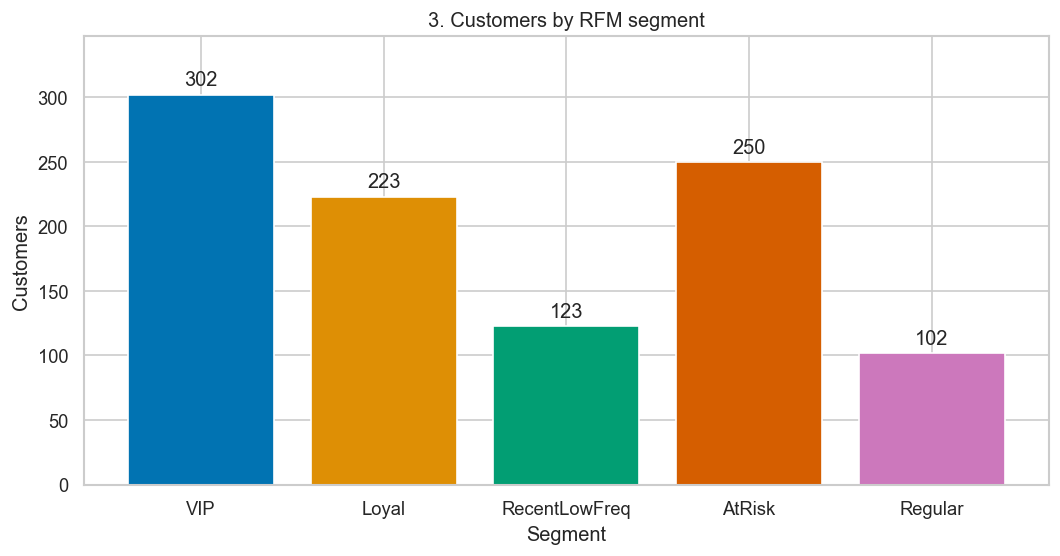

**관찰:** 가장 큰 그룹은 **VIP**, **302명 (30.2%)**이다. **의미:** 캠페인 규모를 산정할 때 이 고객 수를 참고하되 구매금액 기여도도 함께 확인해야 한다.

In [9]:
palette = dict(zip(analyzer.SEGMENTS, sns.color_palette("colorblind", 5)))
fig, ax = plt.subplots()
bars = ax.bar(segments.index, segments.customers, color=[palette[s] for s in segments.index])
ax.bar_label(bars, padding=3)
ax.margins(y=0.15)
ax.set(title="3. Customers by RFM segment", xlabel="Segment", ylabel="Customers")
show_chart(3)
largest = segments.customers.idxmax()
display(Markdown(f"**관찰:** 가장 큰 그룹은 **{largest}**, **{int(segments.loc[largest, 'customers']):,}명 "
                 f"({segments.loc[largest, 'customer_pct']:.1f}%)**이다. "
                 "**의미:** 캠페인 규모를 산정할 때 이 고객 수를 참고하되 구매금액 기여도도 함께 확인해야 한다."))


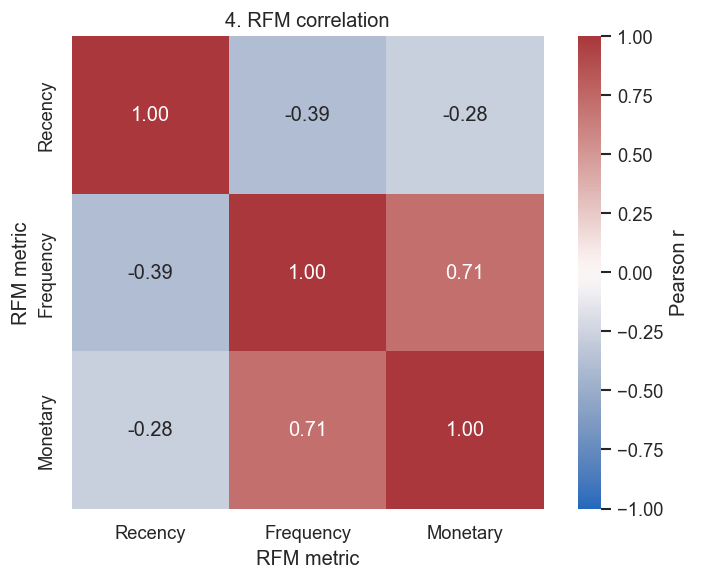

**관찰:** R–F 상관계수는 **-0.392**, F–M 상관계수는 **0.715**이다.

**의미:** R–F는 구매가 오래된 정도와 구매일 수의 동반 변화를 보여주며, 음수이면 최근 고객에서 구매일 수가 많은 경향이다. F–M은 구매일 수와 누적 구매금액의 동반 변화를 보여준다. 구매가 누적되면 금액도 늘기 쉬우므로, 이 계수만으로 방문 증가가 구매금액 증가의 원인이라고 말할 수 없다.

In [10]:
correlation = rfm[["Recency", "Frequency", "Monetary"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
            ax=ax, cbar_kws={"label": "Pearson r"})
ax.set(title="4. RFM correlation", xlabel="RFM metric", ylabel="RFM metric")
show_chart(4)
rf_corr = correlation.loc["Recency", "Frequency"]
fm_corr = correlation.loc["Frequency", "Monetary"]
display(Markdown(f"**관찰:** R–F 상관계수는 **{rf_corr:.3f}**, F–M 상관계수는 **{fm_corr:.3f}**이다.\n\n"
                 "**의미:** R–F는 구매가 오래된 정도와 구매일 수의 동반 변화를 보여주며, 음수이면 최근 고객에서 구매일 수가 많은 경향이다. "
                 "F–M은 구매일 수와 누적 구매금액의 동반 변화를 보여준다. 구매가 누적되면 금액도 늘기 쉬우므로, "
                 "이 계수만으로 방문 증가가 구매금액 증가의 원인이라고 말할 수 없다."))


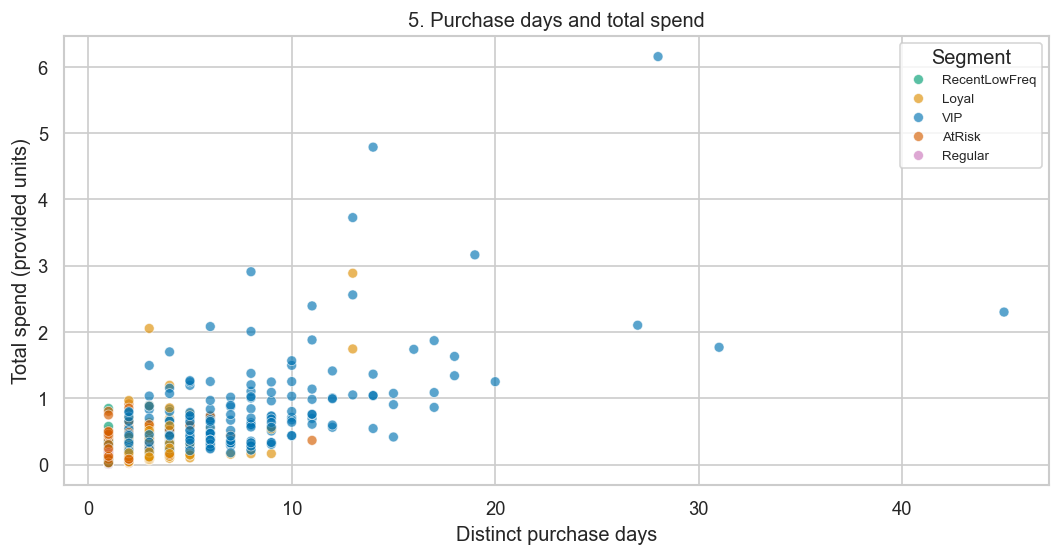

**관찰:** 고객 **1,000명**의 구매일 수는 **1~45일**, 총구매금액은 **0.0068~6.1533**이다. **의미:** 같은 구매일 수에서도 금액이 다른 고객을 구별할 수 있다. 세그먼트는 같은 RFM 값으로 정의했으므로 색의 분리가 독립적인 예측 성능을 뜻하지 않는다.

In [11]:
fig, ax = plt.subplots()
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="segment", palette=palette, alpha=0.65, s=35, ax=ax)
ax.set(title="5. Purchase days and total spend", xlabel="Distinct purchase days", ylabel="Total spend (provided units)")
ax.legend(title="Segment", fontsize=8)
show_chart(5)
display(Markdown(f"**관찰:** 고객 **{len(rfm):,}명**의 구매일 수는 **{rfm.Frequency.min()}~{rfm.Frequency.max()}일**, "
                 f"총구매금액은 **{rfm.Monetary.min():.4f}~{rfm.Monetary.max():.4f}**이다. "
                 "**의미:** 같은 구매일 수에서도 금액이 다른 고객을 구별할 수 있다. 세그먼트는 같은 RFM 값으로 정의했으므로 "
                 "색의 분리가 독립적인 예측 성능을 뜻하지 않는다."))


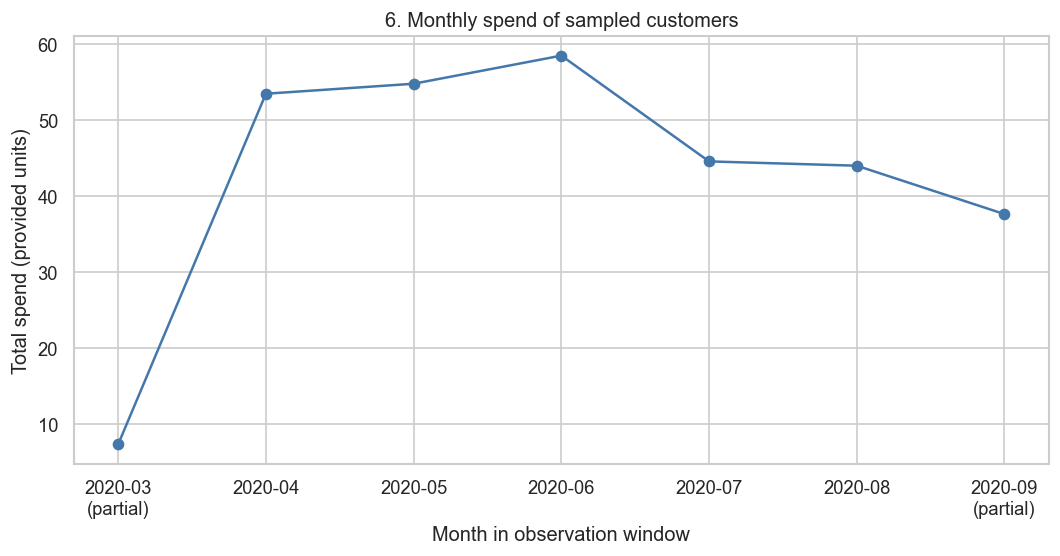

**관찰:** 관찰 구간 **7개 달력월** 중 합계가 가장 큰 월은 **2020-06**, 금액은 **58.4559**, 전체 합계는 **300.2028**이다. **의미:** 월별 규모를 볼 수 있지만 partial은 한 달 전체가 관측되지 않은 구간이다. 이 표본의 월별 금액을 회사 전체 매출이나 동일 관찰 일수의 성장률로 해석하지 않는다.

In [12]:
start, end = pd.Timestamp(meta["window_start"]), pd.Timestamp(meta["reference_date"])
months = pd.period_range(start, end, freq="M")
monthly = df.groupby(df.order_date.dt.to_period("M")).price.sum().reindex(months, fill_value=0)
labels = [str(p) + ("\n(partial)" if p.start_time < start or p.end_time.normalize() > end else "") for p in months]
fig, ax = plt.subplots()
ax.plot(labels, monthly.to_numpy(), marker="o", color="#4477AA")
ax.set(title="6. Monthly spend of sampled customers", xlabel="Month in observation window", ylabel="Total spend (provided units)")
show_chart(6)
peak = monthly.idxmax()
display(Markdown(f"**관찰:** 관찰 구간 **{len(monthly)}개 달력월** 중 합계가 가장 큰 월은 **{peak}**, "
                 f"금액은 **{monthly.loc[peak]:.4f}**, 전체 합계는 **{monthly.sum():.4f}**이다. "
                 "**의미:** 월별 규모를 볼 수 있지만 partial은 한 달 전체가 관측되지 않은 구간이다. "
                 "이 표본의 월별 금액을 회사 전체 매출이나 동일 관찰 일수의 성장률로 해석하지 않는다."))


## 7. 계산 확인과 인사이트 초안

행 수·원본 가격·합계가 보존됐는지 확인하고 고객 그룹 3개에 대한 관찰과 실행 가설을 작성합니다. 기대 효과는 앞으로 검증할 가설입니다.

이 셀은 README의 `ANALYSIS_RESULTS` 표시 사이만 갱신합니다. 다시 실행하면 그 영역을 다시 쓰므로, 본인이 작성한 추가 해석은 표시 바깥에 기록하세요. 오류가 나면 **커널 재시작 → 모두 실행**으로 앞 단계를 순서대로 실행했는지 확인합니다.


In [13]:
assert base_shape[0] >= 1000 and base_shape[1] >= 8
assert pd.api.types.is_datetime64_any_dtype(df.order_date)
assert pd.api.types.is_numeric_dtype(df.price)
assert isinstance(df.product_type_name.dtype, pd.CategoricalDtype)
assert len(df) == meta["transactions"] == base_shape[0]
assert df.customer_id.nunique() == len(rfm) == meta["customers"]
assert np.allclose(raw_price.to_numpy(), df.price.to_numpy())
assert np.isclose(rfm.Monetary.sum(), df.price.sum())
assert np.isclose(monthly.sum(), df.price.sum())
assert analyzer.customers.age.notna().all() and filled_age > 0
assert len(analyzer.image_ids) > 0
assert rfm.segment.nunique() >= 4 and segments.customers.sum() == len(rfm)
assert rfm[["R_score", "F_score", "M_score"]].isin([1, 2, 3, 4]).all().all()
assert np.isfinite([rf_corr, fm_corr]).all(), "상수 변수라 상관계수가 정의되지 않습니다."
assert shown_charts == {1, 2, 3, 4, 5, 6}
print("필수 계산 검증 통과: 행 수·컬럼 수·결측치 대치·원본 금액 보존·RFM 합계·4개 이상 그룹·차트 6개")

actions = {
    "VIP": ("VIP 유지", "VIP 고객에게 우선 구매·멤버십 혜택을 제공해 재구매 유지율 향상을 기대한다.",
            "혜택 비용·마진·후속 구매 데이터가 필요하며, 무작위 대조군보다 순이익이 개선되지 않으면 제안을 재검토한다."),
    "AtRisk": ("장기 미구매 고객 재활성화", "AtRisk 고객에게 구매 이력 기반 재방문 캠페인을 시험해 재구매 전환을 기대한다.",
               "수신 동의·캠페인 노출·후속 구매 데이터가 필요하며, 대조군과 차이가 없으면 미구매 기간만으로 타기팅한 가설을 재검토한다."),
    "RecentLowFreq": ("최근 저빈도 고객의 반복 구매", "RecentLowFreq 고객에게 최근 구매 상품과 관련된 안내를 제공해 다음 구매를 유도한다.",
                      "가입일·관찰 기간 이전 구매·캠페인 반응 데이터가 필요하다. 실제 신규 고객 여부는 현재 표본만으로 확인할 수 없다."),
    "Loyal": ("반복 구매 고객 유지", "Loyal 고객에게 자주 구매한 범주의 혜택을 시험해 구매 간격 유지와 구매금액 증가를 기대한다.",
              "카테고리별 마진·할인 이력·후속 구매 데이터가 필요하며, 할인으로 순이익이 감소하면 혜택 방식을 바꾼다."),
    "Regular": ("일반 고객의 추가 탐색", "Regular 고객을 구매 범주별로 나눠 관련 상품 안내를 시험해 반복 구매를 기대한다.",
                "상품 관심·노출·클릭·후속 구매 데이터가 필요하며, 구매 전환 차이가 없으면 세분화 기준을 재검토한다."),
}
targets = [s for s in ["VIP", "AtRisk", "RecentLowFreq", "Loyal", "Regular"] if s in segments.index][:3]
insights = []
for number, segment in enumerate(targets, 1):
    row = segments.loc[segment]
    title, action, verification = actions[segment]
    insights.append(
        f"### 인사이트 {number}. {title}\n\n"
        f"- **근거:** {segment}는 {int(row.customers):,}명({row.customer_pct:.1f}%)이며, "
        f"평균 미구매 기간 {row.mean_recency_days:.1f}일, 평균 구매일 수 {row.mean_purchase_days:.2f}일, "
        f"평균 총구매금액 {row.mean_monetary:.4f}(제공 단위), 전체 표본 구매금액 비중 {row.monetary_pct:.1f}%다.\n"
        f"- **실행:** {action}\n"
        f"- **검증:** {verification}\n")

table_lines = ["| 그룹 | 고객 수 | 고객 비중 | 평균 R(일) | 평균 F(구매일) | 평균 M(제공 단위) | 금액 비중 |",
               "|---|---:|---:|---:|---:|---:|---:|"]
for name, row in segments.iterrows():
    table_lines.append(f"| {name} | {int(row.customers):,} | {row.customer_pct:.1f}% | {row.mean_recency_days:.1f} | "
                       f"{row.mean_purchase_days:.2f} | {row.mean_monetary:.4f} | {row.monetary_pct:.1f}% |")
result_text = (
    "## 실제 분석 결과\n\n"
    f"실행 입력: 프로젝트 최상위의 샘플 파일 5개. 관찰 기간 **{meta['window_start']}~{meta['reference_date']}**, "
    f"시드 **{meta['seed']}**, 거래 **{len(df):,}행**, 고객 **{len(rfm):,}명**, 상품 **{len(analyzer.articles):,}개**.\n\n"
    f"나이 결측치 **{filled_age:,}명** 대치, 상품 이미지 연결률 **{image_coverage:.2f}%**, "
    f"가격 IQR 탐지 **{out['count']:,}행({out['rate']:.2%})**. 원본 가격은 RFM 계산에 보존했다.\n\n"
    + "\n".join(table_lines) + "\n\n" + "\n".join(insights)
    + "\n근거: [실행된 분석 노트북](notebooks/analysis_report.ipynb)의 RFM 요약표와 차트 3~5. "
      "기대 효과는 실험할 가설이며 이미 달성한 성과가 아니다. 표본 밖 고객이나 관찰 기간 이전 이력으로 일반화하지 않는다.\n")
readme_path = ROOT / "README.md"
existing = readme_path.read_text(encoding="utf-8")
begin, finish = "<!-- ANALYSIS_RESULTS_START -->", "<!-- ANALYSIS_RESULTS_END -->"
assert existing.count(begin) == 1 and existing.count(finish) == 1
prefix, rest = existing.split(begin, 1)
_, suffix = rest.split(finish, 1)
readme_path.write_text(prefix + begin + "\n" + result_text + finish + suffix, encoding="utf-8")
display(Markdown(result_text))
print("README 결과 영역 갱신 완료. 노트북을 Windows Ctrl+S / Mac Cmd+S로 저장하세요.")


필수 계산 검증 통과: 행 수·컬럼 수·결측치 대치·원본 금액 보존·RFM 합계·4개 이상 그룹·차트 6개


## 실제 분석 결과

실행 입력: 프로젝트 최상위의 샘플 파일 5개. 관찰 기간 **2020-03-23~2020-09-22**, 시드 **42**, 거래 **11,153행**, 고객 **1,000명**, 상품 **6,055개**.

나이 결측치 **3명** 대치, 상품 이미지 연결률 **99.87%**, 가격 IQR 탐지 **535행(4.80%)**. 원본 가격은 RFM 계산에 보존했다.

| 그룹 | 고객 수 | 고객 비중 | 평균 R(일) | 평균 F(구매일) | 평균 M(제공 단위) | 금액 비중 |
|---|---:|---:|---:|---:|---:|---:|
| VIP | 302 | 30.2% | 21.0 | 6.06 | 0.6164 | 62.0% |
| Loyal | 223 | 22.3% | 59.1 | 2.87 | 0.2388 | 17.7% |
| RecentLowFreq | 123 | 12.3% | 25.6 | 1.00 | 0.1046 | 4.3% |
| AtRisk | 250 | 25.0% | 136.4 | 1.45 | 0.1566 | 13.0% |
| Regular | 102 | 10.2% | 79.6 | 1.00 | 0.0861 | 2.9% |

### 인사이트 1. VIP 유지

- **근거:** VIP는 302명(30.2%)이며, 평균 미구매 기간 21.0일, 평균 구매일 수 6.06일, 평균 총구매금액 0.6164(제공 단위), 전체 표본 구매금액 비중 62.0%다.
- **실행:** VIP 고객에게 우선 구매·멤버십 혜택을 제공해 재구매 유지율 향상을 기대한다.
- **검증:** 혜택 비용·마진·후속 구매 데이터가 필요하며, 무작위 대조군보다 순이익이 개선되지 않으면 제안을 재검토한다.

### 인사이트 2. 장기 미구매 고객 재활성화

- **근거:** AtRisk는 250명(25.0%)이며, 평균 미구매 기간 136.4일, 평균 구매일 수 1.45일, 평균 총구매금액 0.1566(제공 단위), 전체 표본 구매금액 비중 13.0%다.
- **실행:** AtRisk 고객에게 구매 이력 기반 재방문 캠페인을 시험해 재구매 전환을 기대한다.
- **검증:** 수신 동의·캠페인 노출·후속 구매 데이터가 필요하며, 대조군과 차이가 없으면 미구매 기간만으로 타기팅한 가설을 재검토한다.

### 인사이트 3. 최근 저빈도 고객의 반복 구매

- **근거:** RecentLowFreq는 123명(12.3%)이며, 평균 미구매 기간 25.6일, 평균 구매일 수 1.00일, 평균 총구매금액 0.1046(제공 단위), 전체 표본 구매금액 비중 4.3%다.
- **실행:** RecentLowFreq 고객에게 최근 구매 상품과 관련된 안내를 제공해 다음 구매를 유도한다.
- **검증:** 가입일·관찰 기간 이전 구매·캠페인 반응 데이터가 필요하다. 실제 신규 고객 여부는 현재 표본만으로 확인할 수 없다.

근거: [실행된 분석 노트북](notebooks/analysis_report.ipynb)의 RFM 요약표와 차트 3~5. 기대 효과는 실험할 가설이며 이미 달성한 성과가 아니다. 표본 밖 고객이나 관찰 기간 이전 이력으로 일반화하지 않는다.


README 결과 영역 갱신 완료. 노트북을 Windows Ctrl+S / Mac Cmd+S로 저장하세요.
